#**Taller 5: Integración Por Monte Carlo en Fortran**
Juan Manuel Rosero García - 202437715



In [20]:
#Importamos Fortran
!which gfortran || (apt-get update -qq && apt-get install -y gfortran)
!gfortran --version | head -n 1

/usr/bin/gfortran
GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0


In [21]:
#@title Parte A: Convergencia del estimador de $\pi$
%%writefile taller5_pi.f90
! Taller 5 -- Convergencia del estimador de pi por acierto y error.
! Salidas: convergencia.dat (N, media, desviación) y pendiente.dat (pendiente m).
program taller5_pi
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: M = 20                  ! corridas por cada N
  integer :: k, j, n_sem, u_dat, n_puntos
  integer(8) :: i, n_total, n_aciertos
  integer, allocatable :: semilla(:)
  real(dp) :: u, v, x, y, pi_est, suma, suma2, media, desv
  real(dp) :: X_k, Y_k, sx, sy, sxx, sxy, pendiente

  call random_seed(size=n_sem)
  allocate(semilla(n_sem))

  sx = 0.0_dp; sy = 0.0_dp; sxx = 0.0_dp; sxy = 0.0_dp; n_puntos = 0   ! sumas del ajuste
  open(newunit=u_dat,file='convergencia.dat',status='replace')
  do k = 2, 7                                   ! N = 10^2, ..., 10^7
    n_total = 10_8**k
    suma = 0.0_dp; suma2 = 0.0_dp              ! sumas sobre las M corridas
    do j = 1, M
      semilla = 1000*k + j                    ! una semilla distinta por corrida
      call random_seed(put=semilla)

      !--TODO 1: pi_est con n_total puntos uniformes en el cuadrado--
      n_aciertos = 0
      do i = 1, n_total
        call random_number(u)
        call random_number(v)
        x = 2.0_dp*u - 1.0_dp
        y = 2.0_dp*v - 1.0_dp
        if (x*x + y*y < 1.0_dp) n_aciertos = n_aciertos + 1
      end do
      pi_est = 4.0_dp*real(n_aciertos, dp)/real(n_total, dp)

      !--TODO 2: necesario para la media y la desviación de las M corridas-
      suma = suma + pi_est
      suma2 = suma2 + pi_est*pi_est
    end do

    !--TODO 3: media y desviación estándar de las M estimaciones--
    media = suma/real(M, dp)
    desv = sqrt(suma2/real(M, dp) - media*media)

    write(u_dat,'(i10,2es25.16e3)') n_total,media,desv
    print '(i10,2f12.6)', n_total,media,desv

    !--TODO 4: necesario para ajustar log10(desv) contra log10(N).
    n_puntos = n_puntos + 1
    X_k = log10(real(n_total, dp))
    Y_k = log10(desv)
    sx = sx + X_k
    sy = sy + Y_k
    sxx = sxx + X_k*X_k
    sxy = sxy + X_k*Y_k
  end do
  close(u_dat)

  !--TODO 5: pendiente del ajuste por mínimos cuadrados--
  pendiente = (n_puntos*sxy - sx*sy)/(n_puntos*sxx - sx*sx)

  open(newunit=u_dat,file='pendiente.dat',status='replace')
  write(u_dat,'(es25.16e3)') pendiente
  close(u_dat)
  print '(a,f9.4)', 'Pendiente de log10(s) contra log10(N): ', pendiente
end program taller5_pi

Overwriting taller5_pi.f90


In [22]:
!rm -f convergencia.dat pendiente.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_pi taller5_pi.f90 && ./taller5_pi

       100    3.134000    0.157620
      1000    3.126600    0.048518
     10000    3.137260    0.015422
    100000    3.142696    0.003398
   1000000    3.141116    0.002111
  10000000    3.141530    0.000389
Pendiente de log10(s) contra log10(N):   -0.5079


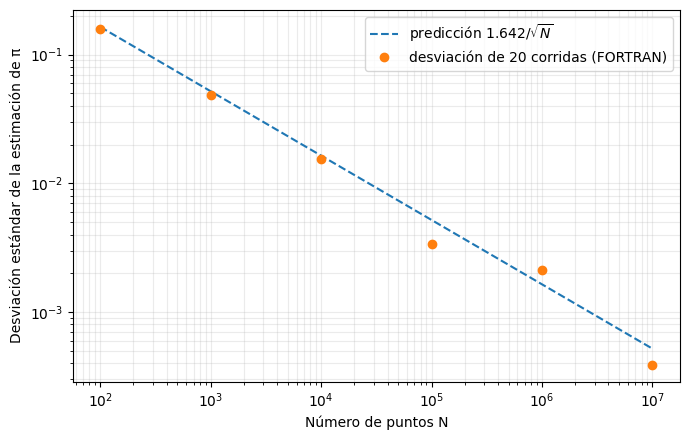

In [23]:
#@title Visualización de la Parte A
import numpy as np
import matplotlib.pyplot as plt

# Lee N, media y desviación calculadas por el programa FORTRAN.
N, media, desv = np.loadtxt('convergencia.dat', ndmin=2).T

plt.figure(figsize=(7,4.5))
plt.loglog(N, 1.642/np.sqrt(N), '--', label=r'predicción $1.642/\sqrt{N}$')
if np.any(desv > 0):
    plt.loglog(N[desv > 0], desv[desv > 0], 'o', label='desviación de 20 corridas (FORTRAN)')
plt.xlabel('Número de puntos N')
plt.ylabel('Desviación estándar de la estimación de π')
plt.grid(True, which='both', alpha=.25)
plt.legend()
plt.tight_layout()
plt.savefig('convergencia_pi.png', dpi=180)
plt.show()

In [24]:
#@title Parte B: Integral por dos métodos
%%writefile taller5_seno.f90
! Taller 5 -- Integral de sin(x) en [0,pi/2) por valor medio y acierto y error.
! Salida: seno.dat (media_vm, desv_vm, media_ae, desv_ae).
program taller5_seno
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: N = 1000, R = 1000      ! muestras por corrida y repeticiones
  real(dp), parameter :: a = 0.0_dp, b = 2.0_dp*atan(1.0_dp), H = 1.0_dp
  integer :: rep, i, n_bajo, n_sem, u_dat
  integer, allocatable :: semilla(:)
  real(dp) :: u, v, x, y, suma_f, I_vm, I_ae
  real(dp) :: s_vm, s2_vm, s_ae, s2_ae, media_vm, desv_vm, media_ae, desv_ae

  ! El tamaño del arreglo de semilla depende de la implementación.
  call random_seed(size=n_sem)
  allocate(semilla(n_sem))
  semilla = 314
  call random_seed(put=semilla)                ! se fija una vez, antes de las R corridas

  s_vm = 0.0_dp; s2_vm = 0.0_dp; s_ae = 0.0_dp; s2_ae = 0.0_dp
  do rep = 1, R
    !--TODO 1: I_vm por valor medio usando N puntos--
    suma_f = 0.0_dp
    do i = 1, N
      call random_number(u)
      x = a + (b-a)*u
      suma_f = suma_f + sin(x)
    end do
    I_vm = (b - a) * suma_f / real(N, dp)

    !--TODO 2: I_ae por acierto y error--
    n_bajo = 0
    do i = 1, N
      call random_number(u)
      call random_number(v)
      x = a + (b-a)*u
      y = H*v
      if (y<sin(x)) n_bajo = n_bajo + 1
    end do
    I_ae = (b - a) * H * real(n_bajo, dp) / real(N, dp)

    !--TODO 3: Las dos integrales y sus cuadrados para las R corridas--
    s_vm = s_vm + I_vm
    s2_vm = s2_vm + I_vm*I_vm
    s_ae = s_ae + I_ae
    s2_ae = s2_ae + I_ae*I_ae
  end do

  !--TODO 4: Media y Desviación estándar muestral--
  media_vm = s_vm/real(R, dp)
  desv_vm = sqrt((real(R,dp)/real(R-1,dp)) * (s2_vm/real(R,dp) - media_vm*media_vm))

  media_ae = s_ae/real(R, dp)
  desv_ae = sqrt((real(R,dp)/real(R-1,dp)) * (s2_ae/real(R, dp) - media_ae*media_ae))


  ! Cuatro números sin encabezado para la lectura automática.
  open(newunit=u_dat,file='seno.dat',status='replace')
  write(u_dat,'(4es25.16e3)') media_vm,desv_vm,media_ae,desv_ae
  close(u_dat)
  print '(a,2f10.5)', 'Valor medio (media, desviacion): ',media_vm,desv_vm
  print '(a,2f10.5)', 'Acierto y error (media, desviacion): ',media_ae,desv_ae
end program taller5_seno

Overwriting taller5_seno.f90


In [25]:
!rm -f seno.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_seno taller5_seno.f90 && ./taller5_seno

Valor medio (media, desviacion):    0.99973   0.01529
Acierto y error (media, desviacion):    1.00009   0.02465


In [26]:
#@title Parte C: Efecto del Generador Deficiente
%%writefile taller5_lcg.f90
! Taller 5 -- pi por acierto y error con el LCG (57, 1, 256) en lugar de random_number.
! Salida: lcg.dat (N, pi_est).
program taller5_lcg
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: a_lcg = 57, c_lcg = 1, M_lcg = 256
  integer :: k, r, u_dat
  integer(8) :: i, n_total, n_aciertos
  real(dp) :: x, y, pi_est

  open(newunit=u_dat,file='lcg.dat',status='replace')
  do k = 2, 7                                   ! N = 10^2, ..., 10^7
    n_total = 10_8**k

    !--TODO 1: pi_est con n_total puntos con coordenadas del LCG--
    n_aciertos = 0
    do i = 1, n_total
      r = mod(a_lcg*r + c_lcg, M_lcg)
      x = 2.0_dp*real(r, dp)/real(M_lcg, dp) - 1.0_dp

      r = mod(a_lcg*r + c_lcg, M_lcg)
      y = 2.0_dp*real(r, dp)/real(M_lcg, dp) - 1.0_dp
      if (x*x + y*y < 1.0_dp) n_aciertos = n_aciertos + 1
    end do
    pi_est = 4.0_dp*real(n_aciertos, dp)/real(n_total, dp)

    write(u_dat,'(i10,es25.16e3)') n_total,pi_est
    print '(i10,f12.6)', n_total,pi_est
  end do
  close(u_dat)
end program taller5_lcg

Overwriting taller5_lcg.f90


In [27]:
!rm -f lcg.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_lcg taller5_lcg.f90 && ./taller5_lcg

       100    3.120000
      1000    3.092000
     10000    3.094000
    100000    3.093680
   1000000    3.093760
  10000000    3.093750


#**Interpretación**

**a) ¿cuántos puntos se necesitarían para obtener $\pi$ con un error de $10^{-6}$? ¿Es práctico?:** Cómo se observa en la gráfica de la parte A, la desviación disminuye aproximadamente como $\frac{1.642}{\sqrt{N}}$. Entonces podemos igualar esta expresión a la presición que deseamos ($10^{-6}$) y despejamos el número de puntos $N$:
$$
\sqrt{N}=\frac{1.642}{10^{-6}} \\
\Rightarrow N=(1.642 \times 10^6)^2 \approx 2.7 \times 10^{12}
$$
Para este método no es práctico porque son muchos lanzamientos para poder lograr 6 decimales de exactitud, de hecho por cada decimal se debe multiplicar $N$ por 100 y esto al final resulta en mucho tiempo de cómputo.

**b) Con el mismo $N$, ¿cuál método de la Parte B tiene menor dispersión? ¿Por qué? ¿Bastaría una sola corrida para afirmarlo?:** El método de Valor Medio tiene menro dispersión, porque saca una mejor información de la curva al evaluar directamente el valor de $sin(x)$; mientras que el método de Acierto y Error solo se reduce a si el tiro cayó dentro o fuera y esto implica una fluctuación mayor.
No es suficiente con una corrida, porque el azar podría dar un excelente resultado o uno muy malo. Para poder contrastar mejor y tener una mayor certeza, se deben realizar varias corridas y luego calcular la desviación estándar de todas.

**c) ¿Por qué, con el LCG de la Parte C, aumentar $N$ no reduce el error, aunque cada número esté en $[0,1)$?:** Este generador no es muy bueno generando números aleatorios y en cierto punto los números se comienzan a repetir, de hecho solo produce 256 valores antes de romperse. Esto hace que al generar parejas aleatorias, solo se producirían 128 puntos distintos. Por más puntos que se generen, no serían datos nuevos, sino repitiendo datos que ya tiene y esto no va a afectar la desviación ni el error de ninguna manera.

**d) ¿Por qué el cálculo de $\pi$ es una integral en 2D, aunque su estimador se escriba como una fracción?:** Aunque parezca una fracción, en realidad estamos midiendo áreas al comparar dos figuras 2D, pues medimos el espacio que ocupa el círculo dentro del cuadrado. Aquí lo interesante es el ingenio para transformar una integral doble (el método matemático para calcular áreas) en una fracción, porque este método de Monte Carlo relaciona el área de un círculo unitario y un cuadrado (que se dan en la región $[-1,1] \times [-1,1]$) y calcula esa probabilidad de que un punto caiga sobre el círculo: $p=\frac{Área del circulo}{Área del cuadrado}=\frac{\pi}{4}$. En el fondo calculamos el área por medio de esa probabilidad, que escribimos como $N_{\text{dentro}}/N$.

In [28]:
#@title Celda de Verificación
from pathlib import Path
import numpy as np

veredictos = []
def informar(nombre, condicion, detalle=''):
    estado = 'PASS' if condicion else 'FAIL'
    veredictos.append(bool(condicion))
    print(f'{estado} | {nombre}' + (f' — {detalle}' if detalle else ''))

def leer_salida(archivo, fuente, columnas):
    ruta, programa = Path(archivo), Path(fuente)
    if not programa.exists() or not ruta.exists():
        raise ValueError(f'Falta {archivo} o {fuente}; ejecute ambas celdas del programa.')
    if ruta.stat().st_mtime < programa.stat().st_mtime:
        raise ValueError(f'{archivo} es anterior a {fuente}; compile y ejecute otra vez.')
    datos = np.loadtxt(ruta, ndmin=2)
    if datos.shape[1] != columnas or not np.isfinite(datos).all():
        raise ValueError(f'Formato o valores incorrectos en {archivo}.')
    return datos

niveles = 10.0**np.arange(2, 8)                # N = 10^2, ..., 10^7

# --- Parte A: media y dispersión de 20 corridas; pendiente calculada en FORTRAN ---
try:
    filas = leer_salida('convergencia.dat','taller5_pi.f90',3)
    if filas.shape != (6,3) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    n, media, desv = filas.T
    sigma = 1.642/np.sqrt(n)
    ok = (abs(media[4]-np.pi) < 6*sigma[4]/np.sqrt(20)
          and np.all((.45*sigma < desv) & (desv < 1.6*sigma)))
    informar('Convergencia de pi', ok,
             f'media(N=10^6)={media[4]:.6f}, s(N=10^6)={desv[4]:.6f}, predicción={sigma[4]:.6f}')
except Exception as error:
    informar('Convergencia de pi',False,str(error))

try:
    n, media, desv = leer_salida('convergencia.dat','taller5_pi.f90',3).T
    m = leer_salida('pendiente.dat','taller5_pi.f90',1)[0,0]
    if len(n) != 6 or not np.all(desv > 0):
        raise ValueError('convergencia.dat debe tener seis desviaciones positivas.')
    m_datos = np.polyfit(np.log10(n), np.log10(desv), 1)[0]
    informar('Pendiente del ajuste en FORTRAN', -.6 < m < -.4 and abs(m-m_datos) < 1e-4,
             f'm={m:.4f}, predicción=-0.5')
except Exception as error:
    informar('Pendiente del ajuste en FORTRAN',False,str(error))

# --- Parte B: integral de sin x por dos métodos ---
try:
    filas = leer_salida('seno.dat','taller5_seno.f90',4)
    if filas.shape != (1,4):
        raise ValueError('seno.dat debe contener media y desviación de cada método.')
    vm, svm, ae, sae = filas[0]
    n, repeticiones = 1000,1000
    sigma_vm = np.sqrt(np.pi**2/8-1)/np.sqrt(n)
    sigma_ae = np.sqrt(np.pi/2-1)/np.sqrt(n)
    ok_vm = (abs(vm-1)<6*sigma_vm/np.sqrt(repeticiones)
             and .65*sigma_vm < svm < 1.35*sigma_vm)
    ok_ae = (abs(ae-1)<6*sigma_ae/np.sqrt(repeticiones)
             and .65*sigma_ae < sae < 1.35*sigma_ae)
    informar('Integral 1D, valor medio',ok_vm,
             f'media={vm:.6f}, dispersión={svm:.6f}')
    informar('Integral 1D, acierto y error',ok_ae,
             f'media={ae:.6f}, dispersión={sae:.6f}')
except Exception as error:
    informar('Integral 1D, valor medio',False,str(error))
    informar('Integral 1D, acierto y error',False,'Revise el mismo programa.')

# --- Parte C: con el LCG la estimación se estanca lejos de pi ---
try:
    filas = leer_salida('lcg.dat','taller5_lcg.f90',2)
    if filas.shape != (6,2) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    pi_lcg = filas[:,1]
    error_lcg = abs(pi_lcg - np.pi)
    ok = .02 < error_lcg[-1] < .2 and abs(pi_lcg[-1]-pi_lcg[-3]) < 1e-3
    informar('Generador deficiente', ok,
             f'|error| con N=10^5: {error_lcg[-3]:.4f}; con N=10^7: {error_lcg[-1]:.4f}')
except Exception as error:
    informar('Generador deficiente',False,str(error))

print(f'\nRESUMEN: {sum(veredictos)}/{len(veredictos)} PASS')
print('Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.')

PASS | Convergencia de pi — media(N=10^6)=3.141116, s(N=10^6)=0.002111, predicción=0.001642
PASS | Pendiente del ajuste en FORTRAN — m=-0.5079, predicción=-0.5
PASS | Integral 1D, valor medio — media=0.999731, dispersión=0.015292
PASS | Integral 1D, acierto y error — media=1.000085, dispersión=0.024645
PASS | Generador deficiente — |error| con N=10^5: 0.0479; con N=10^7: 0.0478

RESUMEN: 5/5 PASS
Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.
